# P2a · Profils horaires des stations BIXI

Les stations BIXI ont-elles des « personnalités » d'usage ? Chaque station est décrite par la répartition de ses départs sur les 24 heures d'un jour de semaine ; les stations sont ensuite regroupées par K-moyennes, puis projetées en deux dimensions par ACP.

Données : BIXI Montréal, historique des déplacements 2025, licence CC BY 4.0, usage non commercial. Le ZIP se place dans `donnees/` (voir le README).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Charte commune des figures du dépôt (style/charte.py) : polices, couleurs, export clair et sombre
sys.path.insert(0, "../../style")
from charte import COULEURS, charger_charte, sauver_clair_et_sombre
charger_charte()
Path("resultats").mkdir(exist_ok=True)

## 1. Lecture des trajets

Le ZIP (317 Mo, un seul CSV de 2,8 Go) se lit sans décompression. Seules 3 des 10 colonnes servent : la station de départ, son arrondissement et l'heure de départ.

In [2]:
chemin_bixi = "donnees/bixi2025.zip"
apercu = pd.read_csv(chemin_bixi, nrows=5)   # 5 lignes, pour voir les colonnes
apercu.T

,0,1,2,3,4
STARTSTATIONNAME,Parc Émilie-Gamelin (St-Hubert / de Maisonneuv...,Métro Mont-Royal (Utilités publiques / Rivard),Notre-Dame / St-Martin,de Maisonneuve / Greene,Métro Sherbrooke (de Rigaud / Berri)
STARTSTATIONARRONDISSEMENT,Ville-Marie,Le Plateau-Mont-Royal,Le Sud-Ouest,Westmount,Le Plateau-Mont-Royal
STARTSTATIONLATITUDE,45.515868,45.524247,45.488302,45.486971,45.518143
STARTSTATIONLONGITUDE,-73.560084,-73.581662,-73.568718,-73.589293,-73.568004
ENDSTATIONNAME,NaN,NaN,NaN,NaN,NaN
ENDSTATIONARRONDISSEMENT,NaN,NaN,NaN,NaN,NaN
ENDSTATIONLATITUDE,NaN,NaN,NaN,NaN,NaN
ENDSTATIONLONGITUDE,NaN,NaN,NaN,NaN,NaN
STARTTIMEMS,1741120865258,1741144108111,1741094909506,1741098869605,1741094527644
ENDTIMEMS,NaN,NaN,NaN,NaN,NaN


In [3]:
colonnes_utiles = ["STARTSTATIONNAME", "STARTSTATIONARRONDISSEMENT", "STARTTIMEMS"]
trajets = pd.read_csv(chemin_bixi, usecols=colonnes_utiles)
len(trajets)

14249363

## 2. Heure de départ locale

`STARTTIMEMS` compte les millisecondes écoulées depuis le 1er janvier 1970, en UTC. La conversion au fuseau `America/Montreal` tient compte de l'heure d'été.

<Axes: xlabel='Heure de départ (Montréal)', ylabel='Trajets'>

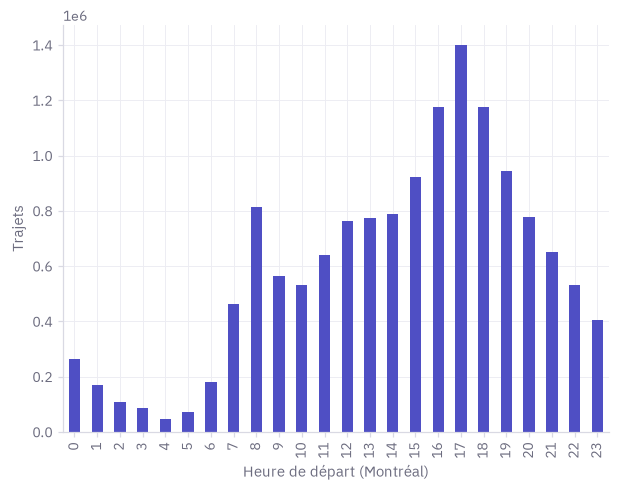

In [4]:
depart_local = (
    pd.to_datetime(trajets["STARTTIMEMS"], unit="ms", utc=True)   # horodatage en UTC
    .dt.tz_convert("America/Montreal")                           # converti à l'heure de Montréal
)
departs_par_heure = depart_local.dt.hour.value_counts().sort_index()
departs_par_heure.plot.bar(xlabel="Heure de départ (Montréal)", ylabel="Trajets")

## 3. Profil horaire de chaque station

Un profil est la part des départs de semaine tombant à chaque heure : 24 valeurs qui somment à 1. Les parts comparent la forme de la journée indépendamment du volume de la station. Seules les stations d'au moins 1 000 départs en semaine sur l'année sont gardées : en dessous, un seul départ pèse trop dans le profil.

In [5]:
en_semaine = depart_local.dt.day_of_week < 5     # lundi = 0 … vendredi = 4
heure_locale = depart_local.dt.hour

departs_semaine = (
    trajets[en_semaine]
    .assign(heure=heure_locale[en_semaine])
    .groupby(["STARTSTATIONNAME", "heure"])
    .size()
    .unstack(fill_value=0)      # une ligne par station, une colonne par heure
)
departs_semaine.shape

(1296, 24)

In [6]:
minimum_departs = 1000
departs_semaine = departs_semaine[departs_semaine.sum(axis=1) >= minimum_departs]
profils = departs_semaine.div(departs_semaine.sum(axis=1), axis=0)   # chaque ligne somme à 1
profils.shape

(948, 24)

## 4. K-moyennes : choix du nombre de groupes

Pour k de 2 à 8 : l'inertie (somme des distances au carré entre chaque station et le centre de son groupe) et la silhouette (de −1 à 1 : une station est-elle plus proche de son groupe que du groupe voisin ?).

,inertie,silhouette
k,,
2,4.152404,0.264225
3,3.485822,0.213361
4,3.196238,0.149826
5,2.966501,0.149094
6,2.829571,0.142433
7,2.695581,0.130303
8,2.585659,0.130629


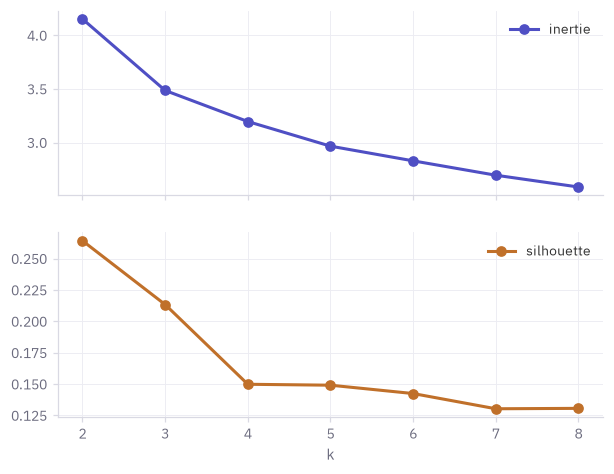

In [7]:
resultats_k = []
for k in range(2, 9):
    # n_init=10 : 10 initialisations, on garde la meilleure ; random_state=0 : résultat reproductible
    modele = KMeans(n_clusters=k, n_init=10, random_state=0).fit(profils)
    resultats_k.append({
        "k": k,
        "inertie": modele.inertia_,
        "silhouette": silhouette_score(profils, modele.labels_),
    })
scores_k = pd.DataFrame(resultats_k).set_index("k")
scores_k.plot(subplots=True, marker="o")
scores_k

Pas de coude net, et une silhouette faible à tous les k (0,26 au mieux, à k = 2) : les profils forment un continuum plus que des groupes tranchés. k = 3 est retenu : deuxième silhouette (0,21), et chaque groupe se nomme clairement.

## 5. Trois profils de stations

groupe
1    435
2    405
0    108
Name: count, dtype: int64

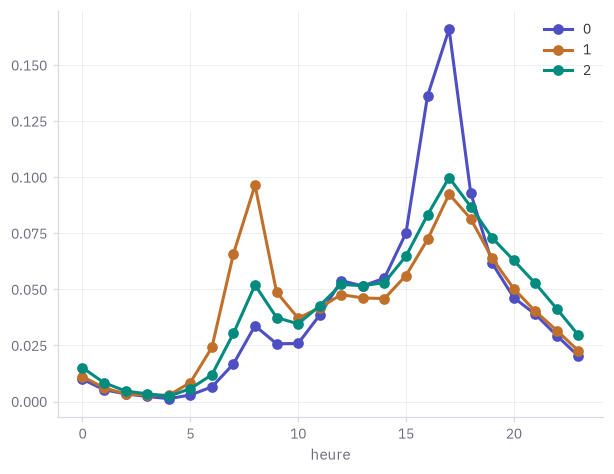

In [8]:
modele_3 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(profils)
groupes = pd.Series(modele_3.labels_, index=profils.index, name="groupe")

centres = pd.DataFrame(modele_3.cluster_centers_, columns=profils.columns)
centres.T.plot(marker="o")      # une courbe par groupe, les 24 heures en x
groupes.value_counts()

In [9]:
arrondissement_par_station = (
    trajets.drop_duplicates("STARTSTATIONNAME")
    .set_index("STARTSTATIONNAME")["STARTSTATIONARRONDISSEMENT"]
)
pd.crosstab(groupes, arrondissement_par_station.reindex(groupes.index)).T

groupe,0,1,2
STARTSTATIONARRONDISSEMENT,,,
Ahuntsic-Cartierville,5,17,13
Anjou,1,0,5
Côte-des-Neiges - Notre-Dame-de-Grâce,1,25,35
LaSalle,2,4,9
Lachine,0,1,8
Laval,3,5,5
Le Plateau-Mont-Royal,8,92,75
Le Sud-Ouest,0,43,27
Longueuil,3,11,12


In [10]:
# Nommer les groupes d'après leur forme : départs de fin de journée rapportés aux départs du matin
part_matin = centres[[7, 8, 9]].sum(axis=1)       # départs de 7 h à 10 h
part_soir = centres[[16, 17, 18]].sum(axis=1)     # départs de 16 h à 19 h
du_matin_au_soir = (part_soir / part_matin).sort_values().index
nom_par_groupe = dict(zip(du_matin_au_soir, ["Résidentiel", "Mixte", "Bureaux"]))
groupe_par_nom = {nom: groupe for groupe, nom in nom_par_groupe.items()}

stations_ville_marie = pd.crosstab(groupes, arrondissement_par_station.reindex(groupes.index))["Ville-Marie"]
resume_groupes = pd.DataFrame({
    "profil": pd.Series(nom_par_groupe),
    "stations": groupes.value_counts(),
    "heure_du_pic": centres.idxmax(axis=1),
    "part_7h_10h": part_matin.round(3),
    "part_16h_19h": part_soir.round(3),
    "stations_ville_marie": stations_ville_marie,
}).sort_values("part_16h_19h")
resume_groupes

,profil,stations,heure_du_pic,part_7h_10h,part_16h_19h,stations_ville_marie
1,Résidentiel,435,8,0.211,0.246,52
2,Mixte,405,17,0.120,0.270,88
0,Bureaux,108,17,0.076,0.396,62


Les stations « bureaux » se vident en fin de journée : on y arrive le matin, on en repart le soir. Les stations résidentielles se vident le matin. Ville-Marie se répartit entre les trois profils : le centre-ville compte aussi des secteurs résidentiels.

## 6. ACP en deux dimensions

part de la variance expliquée par chaque axe : [0.404 0.178]


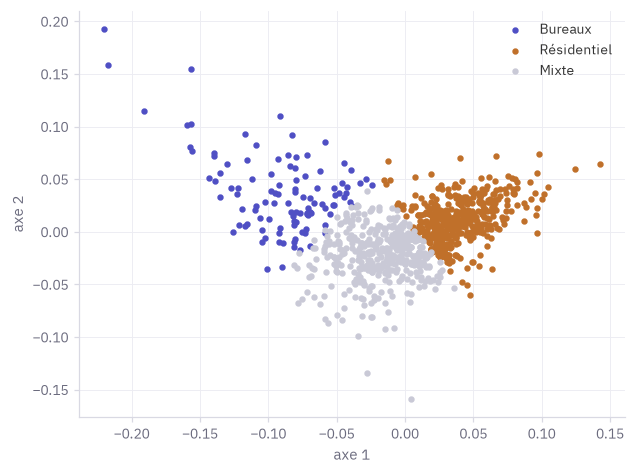

In [11]:
acp = PCA(n_components=2)
coordonnees = acp.fit_transform(profils)        # 948 stations × 2 nombres
print("part de la variance expliquée par chaque axe :", acp.explained_variance_ratio_.round(3))

role_par_profil = {"Bureaux": "accent", "Résidentiel": "second", "Mixte": "neutre"}
for nom, role in role_par_profil.items():
    dans_le_groupe = (groupes == groupe_par_nom[nom]).to_numpy()
    plt.scatter(coordonnees[dans_le_groupe, 0], coordonnees[dans_le_groupe, 1], s=10,
                color=COULEURS["clair"][role], label=nom)
plt.xlabel("axe 1")
plt.ylabel("axe 2")
plt.legend(frameon=False)

<Axes: xlabel='Heure de départ', ylabel="Poids sur l'axe 1">

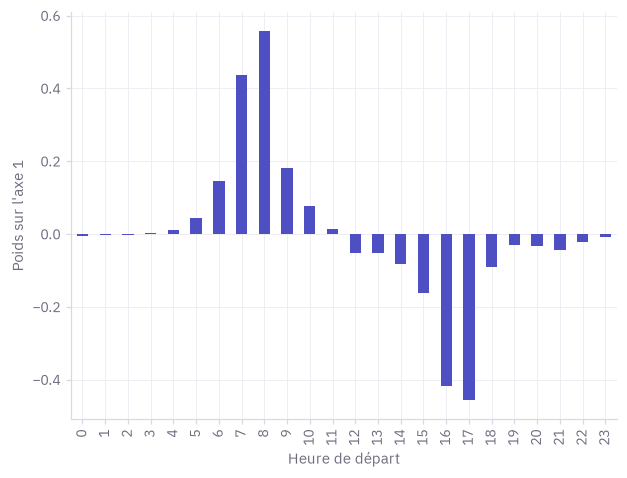

In [12]:
poids_axe_1 = pd.Series(acp.components_[0], index=profils.columns)
poids_axe_1.plot.bar(xlabel="Heure de départ", ylabel="Poids sur l'axe 1")

L'axe 1 (40 % de la variance) oppose les départs du matin (7 h et 8 h) à ceux de fin de journée (16 h et 17 h) : c'est l'axe résidentiel ↔ bureaux. Avec l'axe 2 (18 %), le plan garde 58 % de la variance des profils.

## 7. Contrôle : K-moyennes sans normalisation

Sur les comptes bruts plutôt que sur les parts, les groupes suivent le volume des stations, et non la forme de leur journée.

In [13]:
modele_brut = KMeans(n_clusters=3, n_init=10, random_state=0).fit(departs_semaine)   # comptes, pas parts
volume_par_station = departs_semaine.sum(axis=1)
volume_par_station.groupby(modele_brut.labels_).agg(["count", "median"])

,count,median
0,304,14886.5
1,553,4560.0
2,91,29166.0


## 8. Résultats

In [14]:
scores_k.round(4).to_csv("resultats/choix_k.csv")
resume_groupes.to_csv("resultats/profils_groupes.csv", index=False)
centres.rename(index=nom_par_groupe).round(4).to_csv("resultats/profils_centres.csv", index_label="profil")

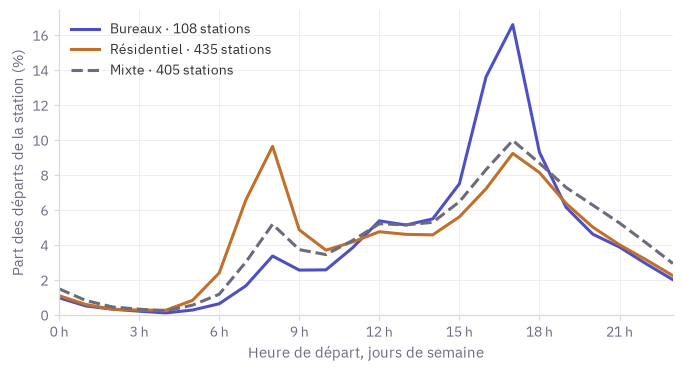

In [15]:
heures = list(range(24))
trait_par_profil = {"Bureaux": ("accent", "-"), "Résidentiel": ("second", "-"), "Mixte": ("trait", "--")}


def tracer_profils(couleurs):
    figure, axe = plt.subplots(figsize=(7.2, 3.6))
    for nom, (role, style_de_trait) in trait_par_profil.items():
        groupe = groupe_par_nom[nom]
        axe.plot(heures, 100 * centres.loc[groupe, heures], color=couleurs[role], linestyle=style_de_trait,
                 linewidth=2, label=f"{nom} · {resume_groupes.loc[groupe, 'stations']} stations")
    axe.set_xticks(range(0, 24, 3), [f"{heure} h" for heure in range(0, 24, 3)])
    axe.set_xlim(0, 23)
    axe.set_ylim(bottom=0)
    axe.set_xlabel("Heure de départ, jours de semaine")
    axe.set_ylabel("Part des départs de la station (%)")
    axe.legend(frameon=False, loc="upper left")
    return figure


sauver_clair_et_sombre(tracer_profils, "resultats/profils_stations")